# CPU Thermal Dynamics & Temperature Prediction

A time-series machine learning and numerical modelling project for understanding and predicting CPU temperature from system workload metrics.

### Project goals

1. Explore real CPU telemetry data and identify thermal patterns.
2. Predict the CPU temperature at the next observation.
3. Compare standard machine-learning baselines with a physics-inspired thermal ODE model.
4. Compare Euler and Runge-Kutta 4 (RK4) numerical integration.
5. Evaluate models using a **time-ordered holdout set** and a continuous recording session.

> **Important:** This project predicts **next-step CPU temperature**. It does not claim to directly predict total cooling time unless a separate cooling-event definition is added.

## 1. Imports and configuration

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", None)

## 2. Load and inspect the dataset

The dataset contains timestamped system measurements such as CPU usage, memory usage, process/thread counts and CPU temperature.

In [4]:
DATA_PATH = "Computer_metrics.csv"

df = pd.read_csv(DATA_PATH)
df["Timestamp"] = pd.to_datetime(df["Timestamp"])
df = df.sort_values("Timestamp").reset_index(drop=True)

display(df.head())
print("Shape:", df.shape)

,Timestamp,CPU_Usage,CPU_Frequency,Memory_Usage,Disk_Usage,Process_Count,Thread_Count,CPU_Temperature,GPU_Temperature
0,2025-12-09 15:29:27.398195,1.0,3793.0,44.3,74.9,186,2687,34.5000,22.000000
1,2025-12-09 15:29:41.518051,1.6,3793.0,44.3,74.9,186,2650,37.3125,22.000000
2,2025-12-09 15:29:48.126377,5.8,3793.0,44.3,74.9,186,2644,39.2500,22.666667
3,2025-12-09 15:29:54.738103,1.4,3793.0,44.3,74.9,186,2628,36.1250,22.333333
4,2025-12-09 15:30:01.383340,12.7,3793.0,45.0,75.0,191,2751,52.3750,23.000000


Shape: (28407, 9)


In [5]:
print("Missing values before cleaning:")
display(df.isna().sum().to_frame("missing"))

display(df.describe(include="all").T)

Missing values before cleaning:


,missing
Timestamp,0
CPU_Usage,0
CPU_Frequency,0
Memory_Usage,0
Disk_Usage,0
Process_Count,0
Thread_Count,0
CPU_Temperature,327
GPU_Temperature,320


,count,mean,min,25%,50%,75%,max,std
Timestamp,28407,2025-12-15 18:07:35.611582,2025-12-09 15:29:27.398195,2025-12-11 21:37:59.179605,2025-12-17 13:55:39.966004,2025-12-18 19:43:52.941948,2025-12-19 23:59:57.201216,NaN
CPU_Usage,28407.0,16.936167,0.0,2.3,8.1,33.25,76.9,17.047437
CPU_Frequency,28407.0,3793.0,3793.0,3793.0,3793.0,3793.0,3793.0,0.0
Memory_Usage,28407.0,52.150463,25.7,36.7,43.5,73.4,91.8,18.533812
Disk_Usage,28407.0,76.490217,73.4,73.9,74.4,78.9,84.1,3.450241
Process_Count,28407.0,184.373499,158.0,174.0,185.0,192.0,228.0,13.663781
Thread_Count,28407.0,2462.588447,1736.0,2263.0,2434.0,2644.0,3604.0,304.131057
CPU_Temperature,28080.0,50.920361,29.625,42.5,49.5625,60.3125,86.9375,11.028116
GPU_Temperature,28087.0,30.83576,19.5,24.166667,27.0,38.333333,60.833333,9.015347


## 3. Data cleaning

CPU temperature is the target variable, so rows without a valid CPU temperature are removed. The original notebook also removed `Disk_Usage` and `GPU_Temperature`; here we keep the main workload variables used by the thermal model and drop the constant CPU frequency column because it contains no useful variation in this dataset.

In [6]:
# Remove rows where the target is unavailable
df = df.dropna(subset=["CPU_Temperature"]).copy()

# CPU_Frequency is constant in this dataset, so it carries no predictive information.
# Keep the other measured workload variables for analysis.
if "CPU_Frequency" in df.columns and df["CPU_Frequency"].nunique() <= 1:
    df = df.drop(columns=["CPU_Frequency"])

print("Shape after cleaning:", df.shape)
display(df.isna().sum().to_frame("missing"))

Shape after cleaning: (28080, 8)


,missing
Timestamp,0
CPU_Usage,0
Memory_Usage,0
Disk_Usage,0
Process_Count,0
Thread_Count,0
CPU_Temperature,0
GPU_Temperature,0


## 4. Exploratory Data Analysis

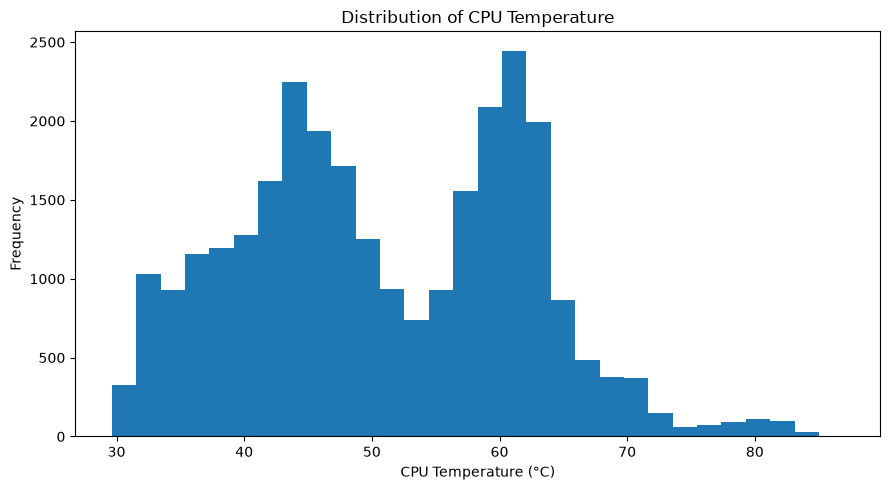

In [7]:
plt.figure(figsize=(9, 5))
plt.hist(df["CPU_Temperature"], bins=30)
plt.xlabel("CPU Temperature (°C)")
plt.ylabel("Frequency")
plt.title("Distribution of CPU Temperature")
plt.tight_layout()
plt.show()

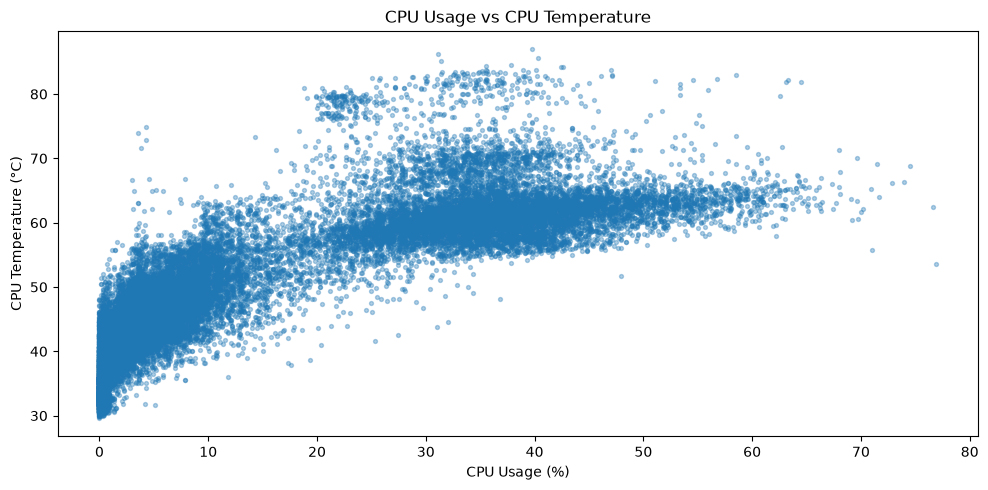

In [8]:
plt.figure(figsize=(10, 5))
plt.scatter(df["CPU_Usage"], df["CPU_Temperature"], s=8, alpha=0.35)
plt.xlabel("CPU Usage (%)")
plt.ylabel("CPU Temperature (°C)")
plt.title("CPU Usage vs CPU Temperature")
plt.tight_layout()
plt.show()

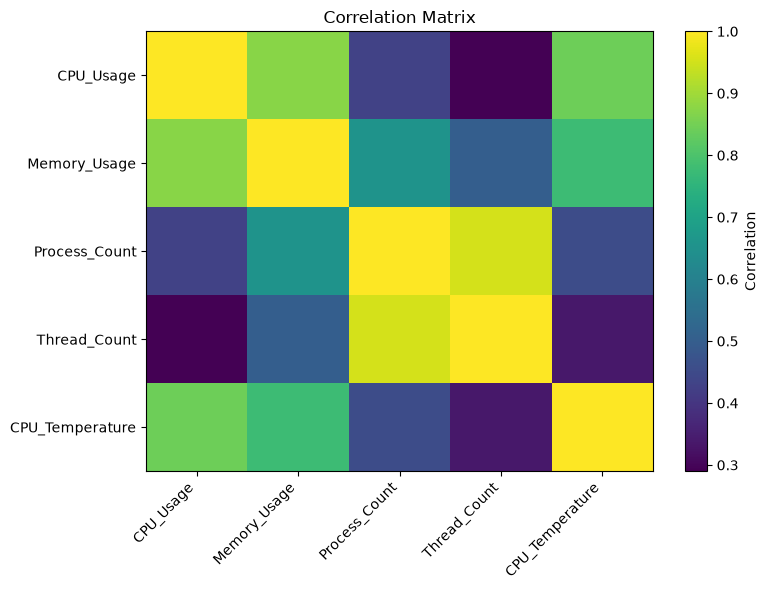

,CPU_Usage,Memory_Usage,Process_Count,Thread_Count,CPU_Temperature
CPU_Usage,1.000,0.875,0.429,0.290,0.842
Memory_Usage,0.875,1.000,0.655,0.503,0.777
Process_Count,0.429,0.655,1.000,0.954,0.455
Thread_Count,0.290,0.503,0.954,1.000,0.337
CPU_Temperature,0.842,0.777,0.455,0.337,1.000


In [9]:
numeric_cols = [
    "CPU_Usage", "Memory_Usage", "Process_Count", "Thread_Count",
    "CPU_Temperature"
]

corr = df[numeric_cols].corr()
plt.figure(figsize=(8, 6))
plt.imshow(corr, interpolation="nearest", aspect="auto")
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

display(corr.round(3))

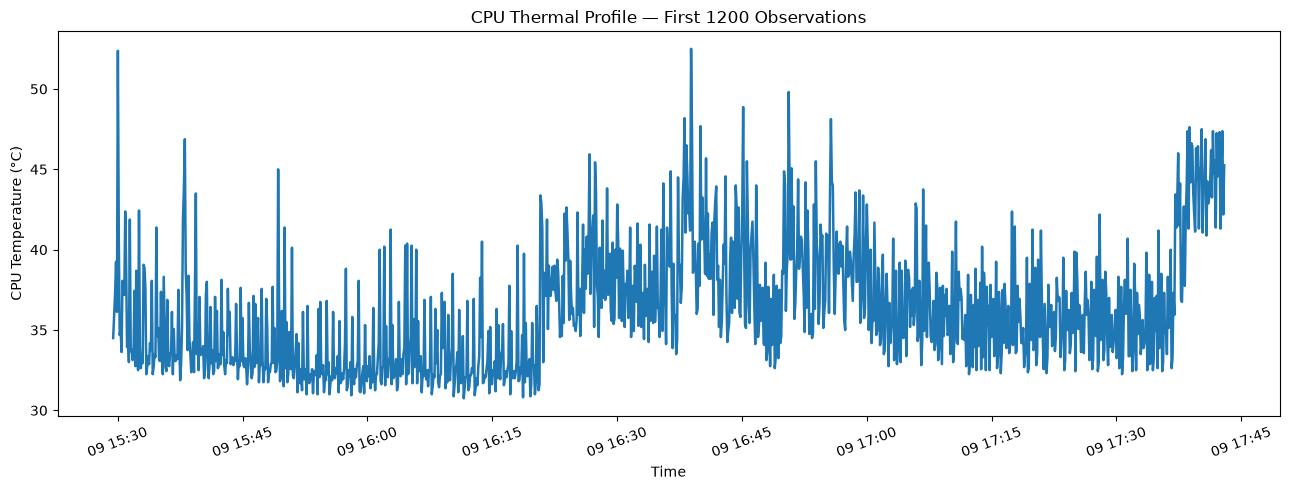

In [10]:
sample = df.iloc[:1200]

plt.figure(figsize=(13, 5))
plt.plot(sample["Timestamp"], sample["CPU_Temperature"], linewidth=1.8)
plt.xlabel("Time")
plt.ylabel("CPU Temperature (°C)")
plt.title("CPU Thermal Profile — First 1200 Observations")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 5. Define the prediction problem

We predict the **next observed CPU temperature** from information available at the current timestamp.

\[
T_{target}=T_{t+1}
\]

This is a one-step-ahead forecasting problem. Because the data are temporal, the evaluation below uses a chronological train/test split instead of randomly shuffling observations.

In [11]:
# Time between consecutive observations, in seconds.
df["dt_seconds"] = df["Timestamp"].diff().dt.total_seconds()

# Next-step target
df["Target_Temperature"] = df["CPU_Temperature"].shift(-1)

# Remove rows without a next observation or a valid time interval
df = df.dropna(subset=["Target_Temperature", "dt_seconds"]).copy()
df = df[df["dt_seconds"] > 0].reset_index(drop=True)

# Approximate temperature derivative for the ODE model
# dT/dt = (T(t+1) - T(t)) / elapsed time
df["dT_dt"] = (
    df["Target_Temperature"] - df["CPU_Temperature"]
) / df["dt_seconds"]

display(df[["Timestamp", "CPU_Temperature", "Target_Temperature", "dt_seconds", "dT_dt"]].head())

,Timestamp,CPU_Temperature,Target_Temperature,dt_seconds,dT_dt
0,2025-12-09 15:29:41.518051,37.3125,39.2500,14.119856,0.137218
1,2025-12-09 15:29:48.126377,39.2500,36.1250,6.608326,-0.472888
2,2025-12-09 15:29:54.738103,36.1250,52.3750,6.611726,2.457755
3,2025-12-09 15:30:01.383340,52.3750,40.6875,6.645237,-1.758779
4,2025-12-09 15:30:07.999627,40.6875,34.6875,6.616287,-0.906853


## 6. Chronological train/test split

The first 80% of observations are used for training and the final 20% are kept completely unseen for evaluation.

In [12]:
feature_cols = [
    "CPU_Temperature",
    "CPU_Usage",
    "Memory_Usage",
    "Process_Count",
    "Thread_Count",
]

split_idx = int(len(df) * 0.80)
train = df.iloc[:split_idx].copy()
test = df.iloc[split_idx:].copy()

X_train = train[feature_cols]
y_train = train["Target_Temperature"]
X_test = test[feature_cols]
y_test = test["Target_Temperature"]

print(f"Training observations: {len(train):,}")
print(f"Test observations:     {len(test):,}")
print(f"Train period: {train['Timestamp'].min()} → {train['Timestamp'].max()}")
print(f"Test period:  {test['Timestamp'].min()} → {test['Timestamp'].max()}")

Training observations: 22,462
Test observations:     5,616
Train period: 2025-12-09 15:29:41.518051 → 2025-12-18 22:26:02.421805
Test period:  2025-12-18 22:26:09.007107 → 2025-12-19 23:59:50.623601


## 7. Machine-learning baselines

Before comparing numerical methods, establish simple predictive baselines.

- **Linear Regression** gives a simple interpretable benchmark.
- **Random Forest** provides a nonlinear tree-based benchmark.

These models predict the next temperature directly rather than modelling the differential equation.

In [13]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
    max_depth=12,
)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

In [14]:
def regression_metrics(y_true, y_pred):
    return {
        "MAE (°C)": mean_absolute_error(y_true, y_pred),
        "RMSE (°C)": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R²": r2_score(y_true, y_pred),
    }

baseline_results = pd.DataFrame({
    "Linear Regression": regression_metrics(y_test, linear_pred),
    "Random Forest": regression_metrics(y_test, rf_pred),
}).T

baseline_results.round(4)

,MAE (°C),RMSE (°C),R²
Linear Regression,2.4410,3.3717,0.9043
Random Forest,2.6534,3.6852,0.8857


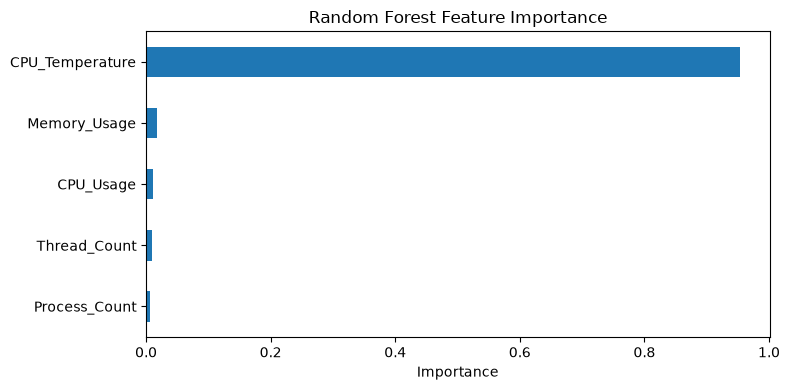

In [15]:
# Feature importance from the Random Forest baseline
importance = pd.Series(rf_model.feature_importances_, index=feature_cols).sort_values(ascending=False)

plt.figure(figsize=(8, 4))
importance.sort_values().plot(kind="barh")
plt.xlabel("Importance")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

## 8. Physics-inspired thermal model

We model the thermal dynamics using a simple first-order ODE:

\[

rac{dT}{dt}=aU+bM-c(T-T_{amb})
\]

where:

- \(T\) = current CPU temperature
- \(U\) = CPU usage
- \(M\) = memory usage
- \(T_{amb}\) = assumed ambient/reference temperature
- \(a,b,c\) = coefficients learned from the **training set only**

The cooling term \(-c(T-T_{amb})\) represents heat dissipation toward the reference temperature.

In [16]:
T_AMBIENT = 25.0

# Fit the ODE coefficients only on the training data to avoid test-set leakage.
X_ode = np.column_stack([
    train["CPU_Usage"].to_numpy(),
    train["Memory_Usage"].to_numpy(),
    -(train["CPU_Temperature"].to_numpy() - T_AMBIENT),
])
y_ode = train["dT_dt"].to_numpy()

a, b, c = np.linalg.lstsq(X_ode, y_ode, rcond=None)[0]

print(f"a = {a:.8f}")
print(f"b = {b:.8f}")
print(f"c = {c:.8f}")

a = -0.00041145
b = 0.00941975
c = 0.01872866


In [17]:
def thermal_model(T, cpu, mem):
    return a * cpu + b * mem - c * (T - T_AMBIENT)


def euler_step(T, cpu, mem, h):
    return T + h * thermal_model(T, cpu, mem)


def rk4_step(T, cpu, mem, h):
    k1 = thermal_model(T, cpu, mem)
    k2 = thermal_model(T + 0.5 * h * k1, cpu, mem)
    k3 = thermal_model(T + 0.5 * h * k2, cpu, mem)
    k4 = thermal_model(T + h * k3, cpu, mem)
    return T + (h / 6.0) * (k1 + 2*k2 + 2*k3 + k4)

## 9. Euler and RK4 predictions on the unseen test period

Unlike the original notebook, the numerical methods now use the **actual elapsed time in seconds** between observations rather than assuming every observation is exactly one unit of time apart.

In [18]:
test = test.copy()

test["Euler_Predicted"] = [
    euler_step(T, cpu, mem, h)
    for T, cpu, mem, h in zip(
        test["CPU_Temperature"],
        test["CPU_Usage"],
        test["Memory_Usage"],
        test["dt_seconds"],
    )
]

test["RK4_Predicted"] = [
    rk4_step(T, cpu, mem, h)
    for T, cpu, mem, h in zip(
        test["CPU_Temperature"],
        test["CPU_Usage"],
        test["Memory_Usage"],
        test["dt_seconds"],
    )
]

display(test[[
    "CPU_Temperature", "Target_Temperature",
    "Euler_Predicted", "RK4_Predicted"
]].head())

,CPU_Temperature,Target_Temperature,Euler_Predicted,RK4_Predicted
22462,59.1250,61.0625,59.028303,59.034029
22463,61.0625,62.0625,60.718602,60.739204
22464,62.0625,61.2500,61.589396,61.617551
22465,61.2500,62.7500,60.880098,60.902248
22466,62.7500,61.8125,62.179937,62.214364


In [19]:
numerical_results = pd.DataFrame({
    "Euler": regression_metrics(test["Target_Temperature"], test["Euler_Predicted"]),
    "RK4": regression_metrics(test["Target_Temperature"], test["RK4_Predicted"]),
}).T

all_results = pd.concat([baseline_results, numerical_results])
all_results.sort_values("RMSE (°C)").round(4)

,MAE (°C),RMSE (°C),R²
Linear Regression,2.441000e+00,3.371700e+00,9.043000e-01
Random Forest,2.653400e+00,3.685200e+00,8.857000e-01
Euler,2.718400e+00,2.705190e+01,-5.160400e+00
RK4,1.641211e+07,1.229923e+09,-1.273416e+16


## 10. Model comparison

A lower MAE/RMSE means the predicted next temperature is closer to the measured temperature. R² closer to 1 indicates that more variance in the target is explained by the model.

,MAE (°C),RMSE (°C),R²
Linear Regression,2.441000e+00,3.371700e+00,9.043000e-01
Random Forest,2.653400e+00,3.685200e+00,8.857000e-01
Euler,2.718400e+00,2.705190e+01,-5.160400e+00
RK4,1.641211e+07,1.229923e+09,-1.273416e+16


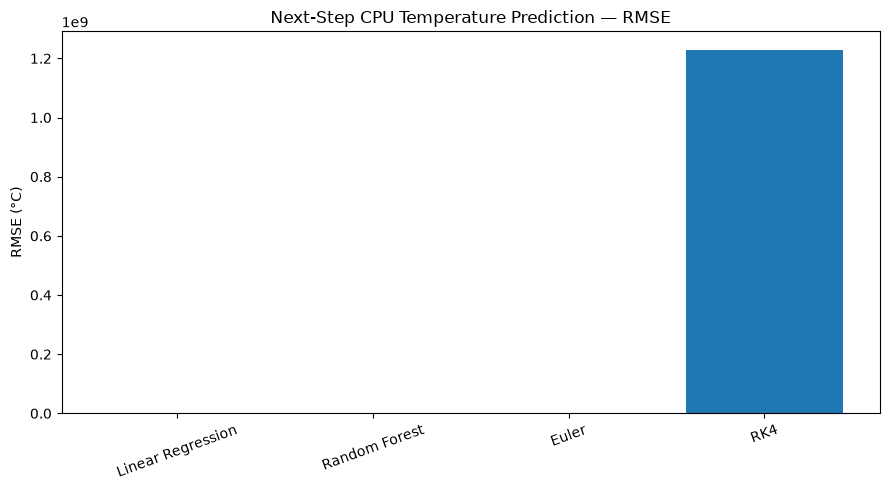

In [20]:
results = all_results.sort_values("RMSE (°C)")
display(results.round(4))

plt.figure(figsize=(9, 5))
plt.bar(results.index, results["RMSE (°C)"])
plt.ylabel("RMSE (°C)")
plt.title("Next-Step CPU Temperature Prediction — RMSE")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 11. Prediction visualization on the test period

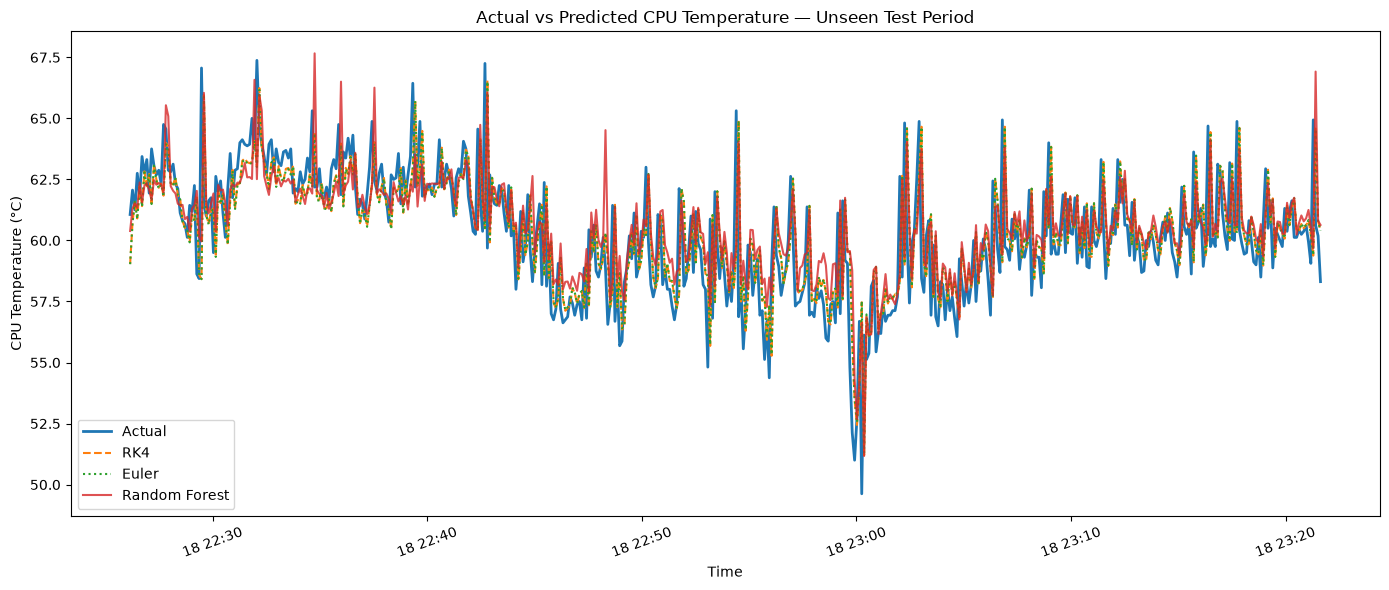

In [21]:
plot_n = min(500, len(test))
sample = test.iloc[:plot_n]

plt.figure(figsize=(14, 6))
plt.plot(sample["Timestamp"], sample["Target_Temperature"], label="Actual", linewidth=2)
plt.plot(sample["Timestamp"], sample["RK4_Predicted"], label="RK4", linestyle="--")
plt.plot(sample["Timestamp"], sample["Euler_Predicted"], label="Euler", linestyle=":")
plt.plot(sample["Timestamp"], rf_pred[:plot_n], label="Random Forest", alpha=0.8)
plt.xlabel("Time")
plt.ylabel("CPU Temperature (°C)")
plt.title("Actual vs Predicted CPU Temperature — Unseen Test Period")
plt.xticks(rotation=20)
plt.legend()
plt.tight_layout()
plt.show()

## 12. Continuous-session validation

The dataset may contain gaps between recordings. To test the thermal model on a more continuous segment, identify the longest session with no gap larger than five minutes.

In [22]:
# Work from the cleaned chronological dataset.
working = df.copy()
working["Time_Gap"] = working["Timestamp"].diff()
working["Session"] = (working["Time_Gap"] > pd.Timedelta(minutes=5)).cumsum()

session_lengths = working.groupby("Session").size().sort_values(ascending=False)
best_session = session_lengths.index[0]
continuous_df = working[working["Session"] == best_session].copy()

print("Longest continuous session:", len(continuous_df), "observations")
print("Start:", continuous_df["Timestamp"].min())
print("End:  ", continuous_df["Timestamp"].max())

Longest continuous session: 6958 observations
Start: 2025-12-11 14:49:22.029102
End:   2025-12-12 03:36:30.917251


In [23]:
continuous_df["RK4_Predicted"] = [
    rk4_step(T, cpu, mem, h)
    for T, cpu, mem, h in zip(
        continuous_df["CPU_Temperature"],
        continuous_df["CPU_Usage"],
        continuous_df["Memory_Usage"],
        continuous_df["dt_seconds"],
    )
]

continuous_df["Euler_Predicted"] = [
    euler_step(T, cpu, mem, h)
    for T, cpu, mem, h in zip(
        continuous_df["CPU_Temperature"],
        continuous_df["CPU_Usage"],
        continuous_df["Memory_Usage"],
        continuous_df["dt_seconds"],
    )
]

continuous_results = pd.DataFrame({
    "Euler": regression_metrics(continuous_df["Target_Temperature"], continuous_df["Euler_Predicted"]),
    "RK4": regression_metrics(continuous_df["Target_Temperature"], continuous_df["RK4_Predicted"]),
}).T

display(continuous_results.round(4))

,MAE (°C),RMSE (°C),R²
Euler,2.127000e+00,1.730980e+01,-2.512200e+00
RK4,1.890934e+08,1.577315e+10,-2.916288e+18


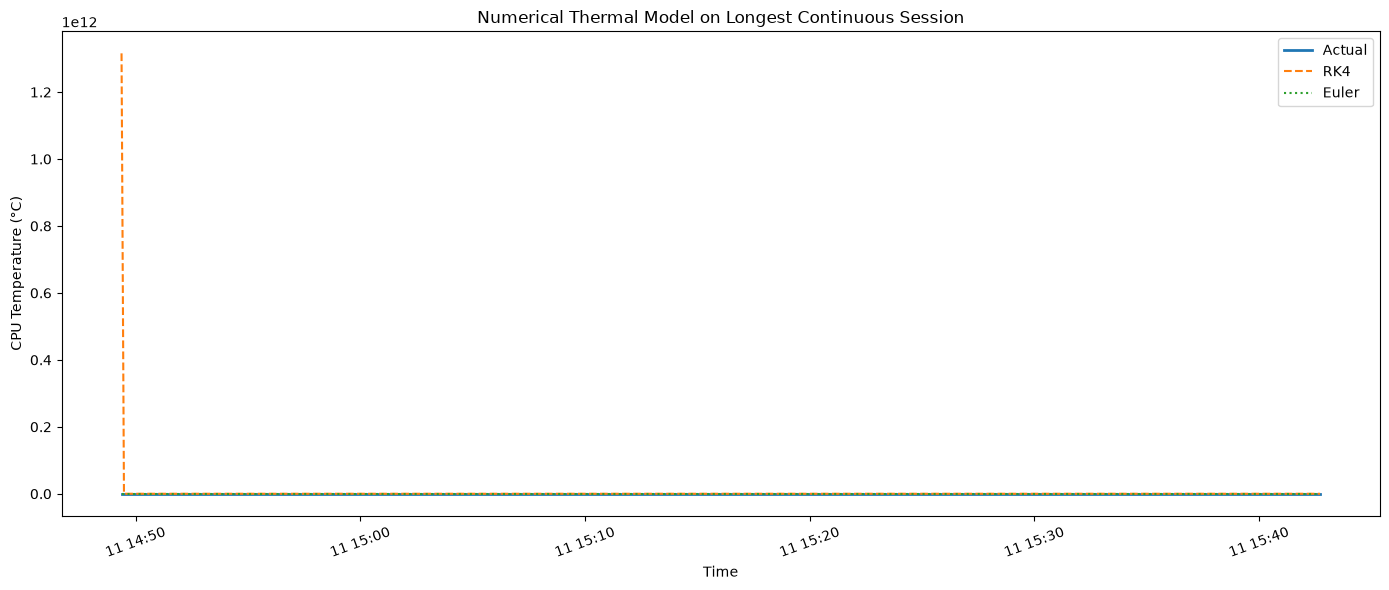

In [24]:
plot_n = min(500, len(continuous_df))
sample = continuous_df.iloc[:plot_n]

plt.figure(figsize=(14, 6))
plt.plot(sample["Timestamp"], sample["Target_Temperature"], label="Actual", linewidth=2)
plt.plot(sample["Timestamp"], sample["RK4_Predicted"], label="RK4", linestyle="--")
plt.plot(sample["Timestamp"], sample["Euler_Predicted"], label="Euler", linestyle=":")
plt.xlabel("Time")
plt.ylabel("CPU Temperature (°C)")
plt.title("Numerical Thermal Model on Longest Continuous Session")
plt.xticks(rotation=20)
plt.legend()
plt.tight_layout()
plt.show()

## 13. Conclusions

### What this project demonstrates

- Real-world CPU telemetry can be treated as a time-series forecasting problem.
- A chronological split gives a more realistic evaluation than randomly shuffling temporal observations.
- Direct ML models and a physics-inspired ODE model provide two different approaches to the same prediction task.
- Euler and RK4 provide a practical comparison of numerical integration methods.
- The continuous-session evaluation tests whether the thermal model behaves consistently over a contiguous recording period.

### Limitations

- The dataset represents one hardware/software environment, so the model may not generalize to other machines.
- Ambient temperature is assumed to be 25°C rather than directly measured.
- The ODE is intentionally simple and uses CPU usage and memory usage as proxies for heat generation.
- The target is **next-step temperature**, not direct cooling-time prediction.

### Possible extensions

1. Collect data from multiple workload types and machines.
2. Add fan speed, power consumption and ambient temperature if available.
3. Predict temperature several steps ahead instead of only one step.
4. Define cooling events and build a separate **time-to-threshold** prediction task.
5. Compare additional models such as Gradient Boosting or XGBoost.